In [1]:
import pandas as pd
import numpy as np

print("Pandas imported successfully")
print("numpy imported succesfuly")

Pandas imported successfully
numpy imported succesfuly


Our project is credit-card fraud detection
 which is a highly imbalanced classification problem
  so accuracy alone is misleading 

# 1 Load dataset 

In [2]:
df=pd.read_csv("/workspaces/credit-card-fraud-detection/data/creditcard.csv")

# 2 understand the data

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
df.shape

(284807, 31)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
df["Class"].value_counts()
#0 = legitimate
#1 = fraud

Class
0    284315
1       492
Name: count, dtype: int64

# 3 Data Cleaning

In [8]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1081)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

# 4 Exploratory Data Analysis

where:

0 → Legitimate transaction
1 → Fraudulent transaction

This is called an imbalanced classification problem

In [11]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [12]:
df["Class"].value_counts(normalize=True)*100 #percentage calc

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [13]:
df[df.duplicated()].head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [14]:
df[df.duplicated()].shape

(1081, 31)

In [15]:
df.columns
#We don't know what V1–V28 individually represent 
# because they are anonymized/PCA-transformed features.

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [16]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [17]:
df["Amount"].skew()
#Most transactions have relatively small amounts, 
# while a small number of transactions have very large amounts.

np.float64(16.977724453761006)

Text(0, 0.5, 'number of transactions')

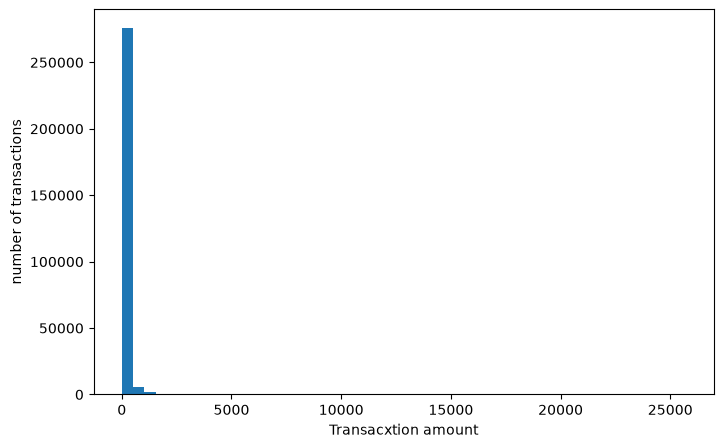

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["Amount"],bins=50)
plt.xlabel("Transacxtion amount")
plt.ylabel("number of transactions")


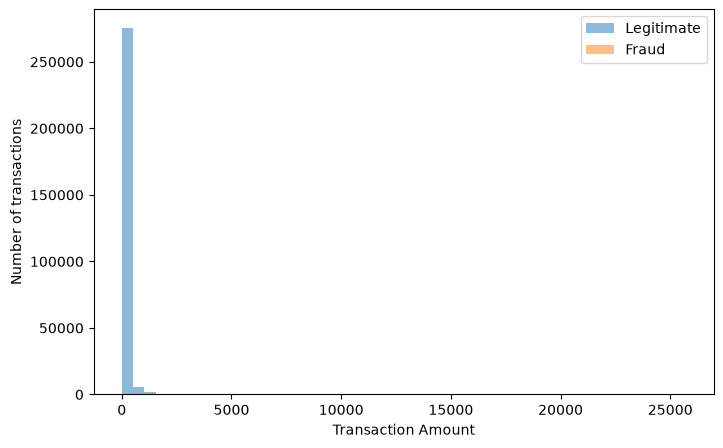

In [19]:
plt.figure(figsize=(8,5))
plt.hist(
    df[df["Class"]==0]["Amount"],
    bins=50,
    alpha=0.5,
    label="Legitimate"
)

plt.hist(
    df[df["Class"]==1]["Amount"],
    bins=1,
    alpha=0.5,
    label="Fraud"
)

plt.xlabel("Transaction Amount")
plt.ylabel("Number of transactions")
plt.legend()


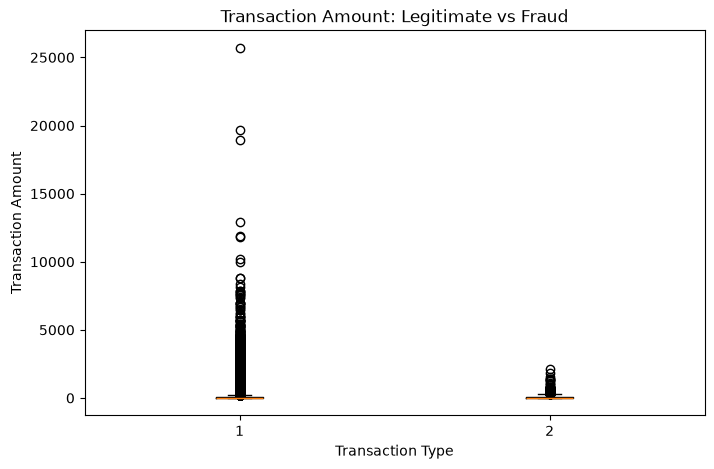

In [20]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df[df["Class"] == 0]["Amount"],
        df[df["Class"] == 1]["Amount"]
    ],
    #labels=["Legitimate", "Fraud"]
)

plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount")
plt.title("Transaction Amount: Legitimate vs Fraud")

plt.show()

In [21]:
#compare avg amount

df.groupby("Class")["Amount"].agg(["count","mean","min","max","std","median"])

,count,mean,min,max,std,median
Class,,,,,,
0,284315,88.291022,0.0,25691.16,250.105092,22.00
1,492,122.211321,0.0,2125.87,256.683288,9.25


# 5 Feature Engineering

Feature Engineering
Creating new useful features from existing data
or transforming existing features, so that a machine-learning model can learn patterns better

In [22]:
df["Time"].describe() #Time = number of seconds elapsed from the first transaction in the dataset

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64

In [23]:
df["Hour"] = ((df["Time"] / 3600) % 24).astype(int)

In [24]:
df["Hour"].describe()

count    284807.000000
mean         14.046470
std           5.835854
min           0.000000
25%          10.000000
50%          15.000000
75%          19.000000
max          23.000000
Name: Hour, dtype: float64

Text(0.5, 1.0, 'transactions by hour')

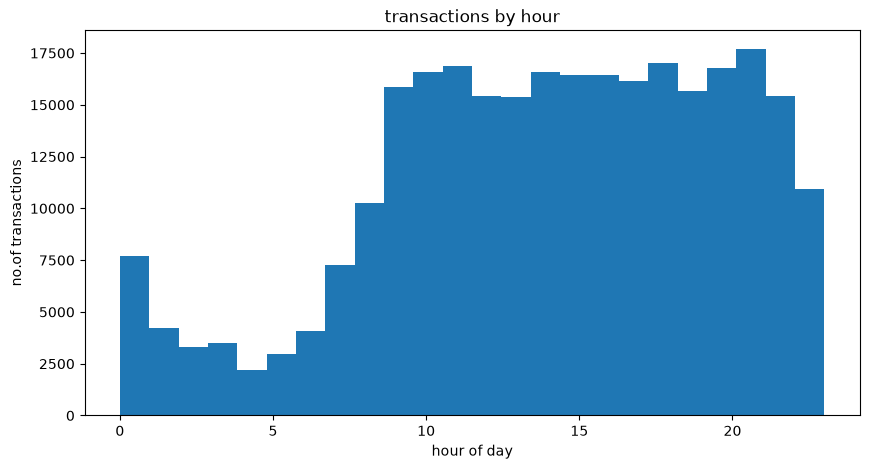

In [25]:
#Look at transactions by hour

plt.figure(figsize=(10,5))

plt.hist(df["Hour"],bins=24)

plt.xlabel("hour of day")
plt.ylabel("no.of transactions")
plt.title("transactions by hour")

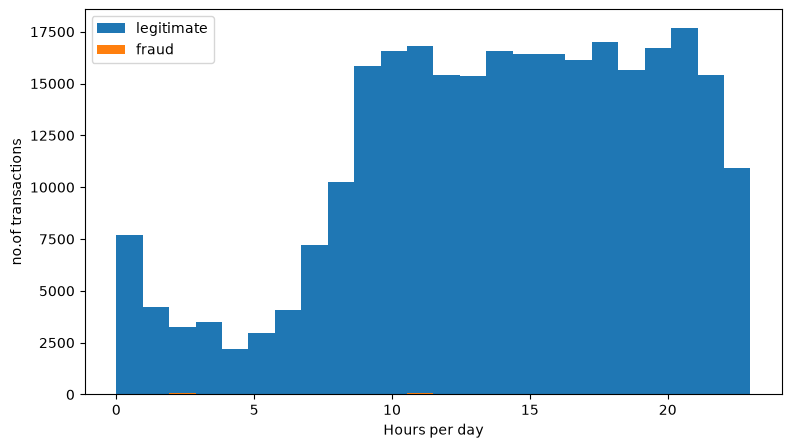

In [26]:
plt.figure(figsize=(9,5))

plt.hist(
    df[df["Class"]==0]["Hour"],
    bins=24,
    label="legitimate"
)

plt.hist(
    df[df["Class"]==1]["Hour"],
    bins=24,
    label="fraud"
    )


plt.xlabel("Hours per day")
plt.ylabel("no.of transactions")
plt.legend()

In [27]:
#calc fraud rate by hour

fraud_rate_by_hour=df.groupby("Hour")["Class"].mean() *100
fraud_rate_by_hour

Hour
0     0.077973
1     0.236967
2     1.712740
3     0.486827
4     1.041195
5     0.367893
6     0.219459
7     0.317548
8     0.087583
9     0.101023
10    0.048199
11    0.314428
12    0.110246
13    0.110641
14    0.138805
15    0.157949
16    0.133714
17    0.179389
18    0.193673
19    0.121414
20    0.107424
21    0.090380
22    0.058286
23    0.191991
Name: Class, dtype: float64

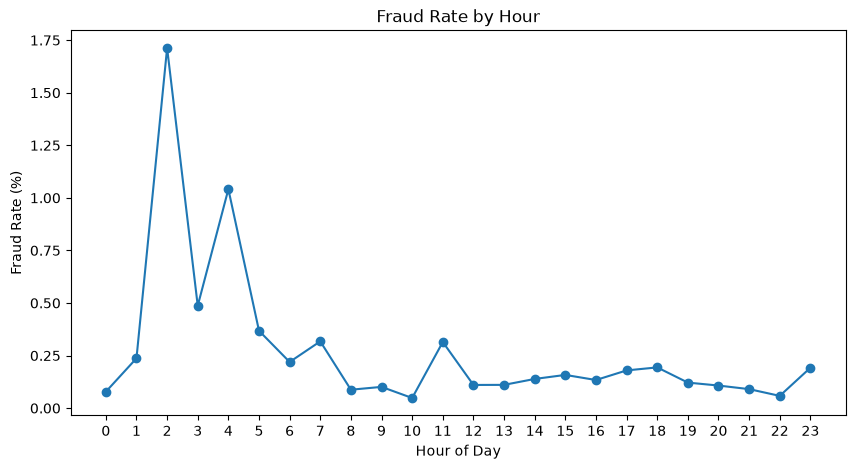

In [28]:
#Visualize the fraud rate by hour
plt.figure(figsize=(10, 5))

plt.plot(
    fraud_rate_by_hour.index, #x axis
    fraud_rate_by_hour.values, #y axis
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Hour")

plt.xticks(range(0, 24))

plt.show()

In [29]:
trans_by_hour=df.groupby("Hour")["Class"].count()
trans_by_hour
#number of transactions per hour

Hour
0      7695
1      4220
2      3328
3      3492
4      2209
5      2990
6      4101
7      7243
8     10276
9     15838
10    16598
11    16856
12    15420
13    15365
14    16570
15    16461
16    16453
17    16166
18    17039
19    15649
20    16756
21    17703
22    15441
23    10938
Name: Class, dtype: int64

In [30]:
#fraud count by hour
fraud_count_by_hour=df.groupby("Hour")["Class"].sum()
#bcz class-> 0 legit 1 fraud ( so sum will be 1+1+1+..... all frauds add)
fraud_count_by_hour

Hour
0      6
1     10
2     57
3     17
4     23
5     11
6      9
7     23
8      9
9     16
10     8
11    53
12    17
13    17
14    23
15    26
16    22
17    29
18    33
19    19
20    18
21    16
22     9
23    21
Name: Class, dtype: int64

Text(0.5, 1.0, 'fraud count')

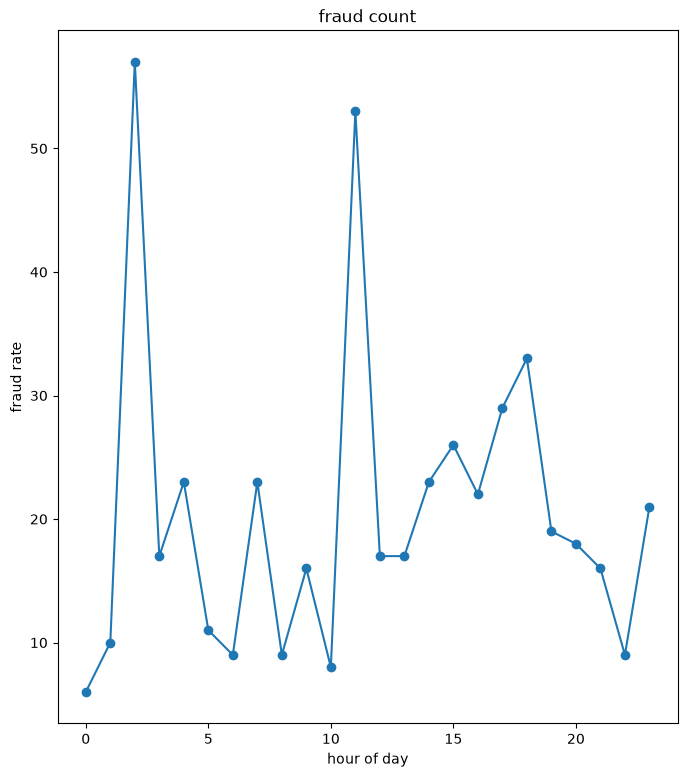

In [31]:
#visualize fraud count

plt.figure(figsize=(8,9))

plt.plot(
    fraud_count_by_hour.index, #x axis  (hours)
    fraud_count_by_hour.values, #y axis (fraud rate values)
    marker="o" #show circle at each point
)

#plt.plot(x_values, y_values)

plt.xlabel("hour of day")
plt.ylabel("fraud rate")
plt.title("fraud count")

# look at our anonymized features v1 v2 .....

In [32]:
correlations =df.corr(numeric_only=True)["Class"].sort_values()
correlations

#if v17 inc class tends to dec

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Hour     -0.017109
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Class     1.000000
Name: Class, dtype: float64

✅ Dataset structure
✅ Missing values
✅ Duplicates
✅ Class imbalance
✅ Amount distribution
✅ Amount skewness
✅ Time analysis
✅ Fraud rate by hour
✅ Correlation with target

<Axes: >

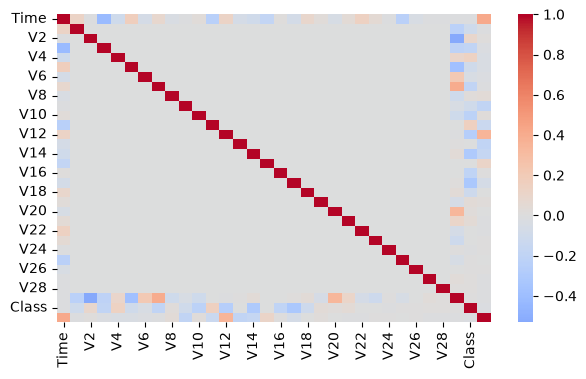

In [33]:
#correlation heatmap
import seaborn as sns
plt.figure(figsize=(7,4))
corr_matrix=df.corr(numeric_only=True)
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0
)

In [34]:
feature_correlations = correlations.drop("Class")

feature_correlations.abs().sort_values(ascending=False) 
#abs bcz neg val is stronger than pos 
#but if abs not used that neg val will come at end insted of start

V17       0.326481
V14       0.302544
V12       0.260593
V10       0.216883
V16       0.196539
V3        0.192961
V7        0.187257
V11       0.154876
V4        0.133447
V18       0.111485
V1        0.101347
V9        0.097733
V5        0.094974
V2        0.091289
V6        0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Hour      0.017109
Time      0.012323
V28       0.009536
V24       0.007221
Amount    0.005632
V13       0.004570
V26       0.004455
V15       0.004223
V25       0.003308
V23       0.002685
V22       0.000805
Name: Class, dtype: float64

# handle duplicate rows

In [35]:
df.shape

(284807, 32)

In [36]:
df=df.drop_duplicates().copy() # remove exact duplicates

In [37]:
df.shape

(283726, 32)

In [38]:
df.duplicated().sum()

np.int64(0)

# prep x and y
x-> input data (all the datas apart frm CLASS)
y-?output data

In [39]:
x=df.drop("Class",axis=1) #drops class  axis=1 (vertical)
y=df["Class"] #keeps only class

In [40]:
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (283726, 31)
y shape: (283726,)


# 6 Train / Validation / Test Split

# split data into training and testing data

In [41]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test =train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  #without stratify =y the split might not be same in test and training data 
    #stratify=y keeps the fraud percentage approximately the same in both sets.
)

In [42]:
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training shape: (226980, 31)
Testing shape: (56746, 31)

Training class distribution:
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64

Testing class distribution:
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


# ML CONCEPTS

# feature scaling
reducing the high feature values to a scalable numerical value so that the high feature values will not dominate the low feature values
it is done by using StandardScaler

# pipeline

pipeline is used to combine diff scaling and modeling steps tgthr into one work flow


In [43]:
x_train.describe().loc[["mean","min","max","std"]]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Hour
mean,94900.224390,0.005027,-0.005549,0.002131,-0.002025,0.004941,-0.001961,0.001480,-0.000215,-0.002883,...,0.001068,0.000073,-0.000230,0.000042,0.000247,0.000306,0.001682,0.000948,88.387124,14.054370
min,0.000000,-56.407510,-72.715728,-33.680984,-5.683171,-32.092129,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-11.710896,0.000000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,21.393069,34.303177,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.016342,7.519589,3.517346,12.152401,33.847808,19656.530000,23.000000
std,47488.214282,1.947293,1.649617,1.507270,1.416960,1.359643,1.323401,1.200181,1.169342,1.094055,...,0.722252,0.724366,0.625700,0.605816,0.521633,0.481386,0.390579,0.325749,245.767046,5.828895


# Logistic Regression

In [44]:
from sklearn.pipeline import Pipeline #connects ML steps tgthr
from sklearn.preprocessing import StandardScaler #standardises the features (feature scaling)
from sklearn.linear_model import LogisticRegression #our 1st CLASSIFICATION algorithm

In [45]:
#we r storing pipeline in var logistic_model
logistic_model=Pipeline(
    [
        #name of the step and the actual step to perform
        ("scalaer",StandardScaler()), #standard scaler  transforms the MEAN into 0 and SD into 1

        #after scaling the data train logistic reg model
        ("model",LogisticRegression(
            max_iter=1000, #1000 iterations maximum
            class_weight="balanced",
            #BALANCED informs the reg that dont treat all the classes equally 
            #give MORE IMPORTANCE TO minority class (legit - less imp , fraud - more imp) 
            # bcz majority class r legit and minority cls are fraud
            #so the minority class (fraud) will not be neglected.
            random_state=42
            #use same random seed to produce same random numbers
        ))
    ]
)

# train the model

logistic_model.fit(x_train,y_train)

.fit refers to Learn from the training data 

x_train contains input featurs (indeo featurs) v1 v2 amt........(other than class)
 y_train contains CORRECT ANSWERS for each training row

#x_train->question
#y_train->correct answer

it means train the complete pipeline using training data

(pipeline)-> x_train + y_train ->StandardScalar ->Logistic Regression -> learn parameters

In STANDARDSCALAR formula is used z=x-mui/sigma (to make mean =0 sd =1)
In LOGISTIC REGRESSION z=w1​x1​+w2​x2​+w3​x3​+⋯+b performed and then passed into sigmoid func 

In [46]:
logistic_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scalaer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['Time','V1','V2',...,'V28','Amount','Hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [47]:
y_pred=logistic_model.predict(x_test)
y_pred
#Using what we learned during training, 
# predict the classes for these new/test observations.
#for prediction we use x_test
#for evaluation we use y_test

#it uses the model's default classification threshold.

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

In [ ]:
y_pred.sum() #it returned 1496 which r frauds bcz frauds r considered as 1 and legit r considered as 0 
# so sum up value will be adding all ones which gives us num of fraud predictions

np.int64(1496)

In [ ]:
np.unique(y_pred,return_counts=True)

(array([0, 1]), array([55250,  1496]))

In [50]:
y_pred_prob = logistic_model.predict_proba(x_test)[:, 1]
y_pred_prob

array([0.03845552, 0.02457597, 0.00822003, ..., 0.07086761, 0.02677807,
       0.03144953], shape=(56746,))

predict()-> gives final output that is 
it says which class the model predicts
predict_proba()->give probability of the pos and neg output
ex->
legit 0.9 , fraud 0.1

predict_proba() is imp bcz 
trans  a->  f->0.49
TRANS B-> F-> 0.51
if our normal THRESHOLD Value is 0.50 then 
A will be legit B will be fraud

If bank wants it more strict (threshold tuning can be done)
and if threshold is changed to 0.30
then both tans will be false

# confusion matrix 
(to evaluate the model)

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
cm_lr=confusion_matrix(y_test,y_pred)

this confusion matrix gives tables
|                           | Predicted Legitimate (0) | Predicted Fraud (1) |
| ------------------------- | -----------------------: | ------------------: |
| **Actual Legitimate (0)** |               **55,238** |           **1,413** |
| **Actual Fraud (1)**      |                   **12** |              **83** |


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

#56,651 legitimate transactions
#95 fraud transactions

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.97      0.99     56746



56,651 legitimate transactions
95 fraud transactions
(imbalanced data bcz for cls 0-> 56k data clas 1 -> 95 data)

# precision
Out of trans that model predicted as positive how many are actually positive

case->0 ==> model predicted 100% correct legit values
case->1 ==> model predicted only 6% correct frauds  (out of wt the model predicted as fraud only 6 % r actually fraud)
In other words  model is saying "Class 1!" for many samples that are actually class 0.

 # class_weight="balanced"  tells the model:

    #"g ive more importance to mistakes involving the minority fraud class." 
    # Therefore, the model becomes more willing to classify transactions as fraud.

Precision=TP/FP+TP​

# recall
Out of all positive cases how many did the model find 

case 0 -> Out of 100% legit valyes model found 98% legit values
case 1 -> out of 100 % fraud values model found 87% fraud values

Recall=TP/FN+TP​

# F1 
Comb of prec and recall

# Accuracy
out of everything how many predictions are correct
(here 0.97 ->97 % correct)
Accuracy can be misleading with imbalanced datasets

                 LOGISTIC REGRESSION

              56,746 test transactions
                        │
             ┌──────────┴──────────┐
             ↓                     ↓
       Legitimate                 Fraud
        actual                   actual
        56,651                     95
             │                     │
             ↓                     ↓
       Mostly detected       83 detected (87 %)
                             12 missed

Also
1413 legitimate transactions
          ↓
incorrectly flagged as fraud

# for class 1 
High recall
     ↓
Catches most frauds

BUT

Very low precision
     ↓
Flags many genuine transactions as fraud

In [54]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc_lr = roc_auc_score(y_test, y_pred_prob)
pr_auc_lr = average_precision_score(y_test, y_pred_prob)

print("ROC-AUC:", roc_auc_lr)
print("PR-AUC:", pr_auc_lr)

#ROC-AUC and PR-AUC use the prob rather than just the final 0/1 predictions.

ROC-AUC: 0.9684760523575093
PR-AUC: 0.6682756600936479


# store the values into one table

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_lr = accuracy_score(y_test, y_pred)
precision_lr = precision_score(y_test, y_pred)
recall_lr = recall_score(y_test, y_pred)
f1_lr = f1_score(y_test, y_pred)

In [ ]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_lr,
    "Precision": precision_lr,
    "Recall": recall_lr,
    "F1": f1_lr,
    "ROC-AUC": roc_auc_lr,
    "PR-AUC": pr_auc_lr
}

# ROC 
Receiver Operating Characteristic
"As we change the  threshold value, how well can the model separate fraud from genuine transactions?"

AUC means:
Area Under the ROC Curve.

The closure the AUC is to 1 , the model seperates 2 classes well accross the thresholds

Our ROC-AUC  0.96 -> The model is generally good at assigning higher fraud scores to fraudulent transactions than to genuine ones.

ROC-AUC considers:
TPR vs FPR

PR-AUC considers:
Precision vs Recall

# PR AUC (Precision-Recall)


Our dataset is extremely imbalanced.

That's where PR-AUC becomes especially important.

PR AUC asks -> When I focus on identifying the rare fraud class, how well do precision and recall behave across thresholds?



"What does ROC-AUC of 0.968 and PR-AUC of 0.668 mean for your fraud detection model?"


"ROC-AUC of 0.968 indicates that the Logistic Regression model has strong discrimination between fraudulent and legitimate transactions across classification thresholds. 

PR-AUC of 0.668 is particularly relevant because the dataset is highly imbalanced. 
It indicates the model maintains a meaningful precision-recall trade-off for the minority fraud class. 
I would not interpret ROC-AUC as 96.8% accuracy; 

Because the dataset is highly imbalanced, I evaluated the model using precision, recall, F1, ROC-AUC and PR-AUC rather than relying on accuracy alone."

I would evaluate the model further using precision, recall, F1-score and the confusion matrix at the selected operating threshold."

We are keeping the data as it is for logistic regression to use it as 
# baseline 
and comapre with decision tree

# decision tree


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model=DecisionTreeClassifier(
    max_depth=8, #used to avoid OVER FITTING (if not mentioned it'll go to all the depths and memorize the data)
    min_samples_split=10, #A node shld have min samples of 10 before it splits ... it prevents tiny branches
    #(How many samples must be present in a node before I am allowed to split it)
    min_samples_leaf=5, #this is after split ..... once the parent node is splitted ex into 15 parts  
     #the tree is splitted into 13 left and 2 right its not accepted 
     # bcz min leaf node is 5 so both left and right nodes shld be greater than 5 otherwise its not accepted
    class_weight="balanced",
    random_state=42
)

Standard scalar is not needed bcz for decision tree it is not req to perform feature scaling

In [58]:
dt_model.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fea

In [ ]:
y_pred_dt=dt_model.predict(x_test)
y_pred_dt

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

In [ ]:
y_prob_dt=dt_model.predict_proba(x_test)[:,1]
y_prob_dt

array([0., 0., 0., ..., 0., 0., 0.], shape=(56746,))

In [61]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56651
           1       0.14      0.80      0.24        95

    accuracy                           0.99     56746
   macro avg       0.57      0.90      0.62     56746
weighted avg       1.00      0.99      0.99     56746



In [ ]:
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)
pr_auc_dt = average_precision_score(y_test, y_prob_dt)

print("ROC-AUC:", roc_auc_dt)
print("PR-AUC:", pr_auc_dt)

ROC-AUC: 0.9073716355636403
PR-AUC: 0.49634465864752325


In [ ]:
cm= confusion_matrix(y_test,y_pred_dt)
cm

array([[56177,   474],
       [   19,    76]])

In [ ]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

In [ ]:
dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1": f1_dt,
    "ROC-AUC": roc_auc_dt,
    "PR-AUC": pr_auc_dt
}

# RANDOM FOREST
Its' BAGGING
A single Decision Tree might make mistakes
Random Forest builds many decision trees
It's an Ensembling tech

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model= RandomForestClassifier(
    n_estimators=100, #creates 100 decision trees 
    n_jobs=1, #Use all available CPU cores to run the computation in parallel
    class_weight="balanced",
    random_state=42
)

In [67]:
rf_model.fit(x_train,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [68]:
y_pred_rf=rf_model.predict(x_test)
y_pred_rf

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

In [ ]:
y_prob_rf= rf_model.predict_proba(x_test)[:,1] #[:,1]Select the probability of class 1 = fraud.

In [70]:
#evaluate

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [71]:
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("ROC-AUC:", roc_auc_rf)

ROC-AUC: 0.9339712496365095


In [72]:
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("PR-AUC:", pr_auc_rf)

PR-AUC: 0.808865476231317


In [73]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[56648     3]
 [   26    69]]


In [ ]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

In [ ]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1": f1_rf,
    "ROC-AUC": roc_auc_rf,
    "PR-AUC": pr_auc_rf
}

# XG boost

XGBoost is a powerful gradient-boosting tree algorithm.

diff b/w Rf and XG
RF-->Builds many trees more independently and combines them. (BAGGING)

XG-->Builds trees sequentially with later trees focusing on errors made by earlier trees. (BOOSTING)

In [76]:
import xgboost
print(xgboost.__version__)

3.4.1


In [ ]:
import xgboost
print(xgboost.__version__)

3.4.1


In [ ]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos_weight = neg / pos  # Find how many times more common genuine transactions are than fraud transactions

print("Negative:", neg)
print("Positive:", pos)
print("scale_pos_weight:", scale_pos_weight)

Negative: 226602
Positive: 378
scale_pos_weight: 599.4761904761905


In [ ]:
from xgboost import XGBClassifier


In [ ]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05, #How much each new tree contributes to the final model.
    #Lower values make learning slower and usually require more trees.
    max_depth=5,
    subsample=0.8, #specify the usage of TRAINING ROWS (each tree uses 80% of training rows)

    #subsample = rows
    #colsample_bytree = columns
    # Both can help reduce overfitting.
    colsample_by_tree=0.8, #specify the usage of cols/features
    scale_pos_weight=scale_pos_weight, #Give more importance to the positive(1)/fraud class during training.


    eval_metric="logloss", #While you are training, use Log Loss to measure how good your predicted probabilities are
    #The smaller the log loss, the better.

    random_state=42,
    n_jobs=-1

#n_jobs=1 → use 1 CPU core
#n_jobs=2 → use 2 cores
#n_jobs=-1 → use all available CPU cores

)

In [81]:
xgb_model.fit(x_train,y_train)

/workspaces/credit-card-fraud-detection/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [02:36:48] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "colsample_by_tree" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [82]:
y_pred_xgb=xgb_model.predict(x_test)
y_pred_xgb

array([0, 0, 0, ..., 0, 0, 0], shape=(56746,))

In [ ]:
y_prob_xgb=xgb_model.predict_proba(x_test)[:,1]

In [ ]:
cm_xgb=confusion_matrix(y_test,y_pred_xgb)

In [85]:
print(classification_report(y_test,y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.88      0.81      0.84        95

    accuracy                           1.00     56746
   macro avg       0.94      0.91      0.92     56746
weighted avg       1.00      1.00      1.00     56746



In [86]:
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)
pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)

print("XGBoost ROC-AUC:", roc_auc_xgb)
print("XGBoost PR-AUC:", pr_auc_xgb)

XGBoost ROC-AUC: 0.9741679665616529
XGBoost PR-AUC: 0.8087962064943646


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

In [ ]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_xgb,
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1": f1_xgb,
    "ROC-AUC": roc_auc_xgb,
    "PR-AUC": pr_auc_xgb
}

# combining all results

In [ ]:
all_results = [
    lr_results,
    dt_results,
    rf_results,
    xgb_results
]

In [ ]:
results_df = pd.DataFrame(all_results)

In [ ]:
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.974888,0.055481,0.873684,0.104337,0.968476,0.668276
1,Decision Tree,0.991312,0.138182,0.800000,0.235659,0.907372,0.496345
2,Random Forest,0.999489,0.958333,0.726316,0.826347,0.933971,0.808865
3,XGBoost,0.999489,0.875000,0.810526,0.841530,0.974168,0.808796


In [ ]:
print("Logistic Regression")
print(cm_lr)

print("\nDecision Tree")
print(cm)

print("\nRandom Forest")
print(cm_rf)

print("\nXGBoost")
print(cm_xgb)

Logistic Regression
[[55238  1413]
 [   12    83]]

Decision Tree
[[56177   474]
 [   19    76]]

Random Forest
[[56648     3]
 [   26    69]]

XGBoost
[[56640    11]
 [   18    77]]


 # conclusion
"I compared Logistic Regression, Decision Tree, Random Forest, and XGBoost rather than relying on a single algorithm because different models capture different patterns and have different strengths. I started with Logistic Regression as a baseline, then evaluated tree-based models and boosting. Since credit-card fraud detection is highly imbalanced, I did not rely on accuracy alone. I compared precision, recall, F1-score, ROC-AUC, PR-AUC, and the confusion matrix. XGBoost gave the best overall balance in my experiments, with an F1-score of approximately 0.842 and ROC-AUC of approximately 0.974, while Random Forest had slightly better precision. The final model choice would ultimately depend on the business cost of false positives versus false negatives."

 Accuracy is one 1 ..... This is because the dataset is extremely imbalanced. (only 95 frauds and 50k+ legits)

Now we will go to hyperparameter tuning

Change the params inside the xgboost ... like the depth, learning rate and etx.. (tuning the model itself)


# Hyper parameter tuning

For this we use Cross Validation

Cross-validation  is a technique used to check whether your model performs well on different subsets of the training data
instead of depending on just one train/validation split.

The most common type is K-Fold Cross-Validation.

GridSearchCV does this automatically

In [ ]:
print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_by_tree=0.8, colsample_bylevel=None,
              colsample_bynode=None, colsample_bytree=None, device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric='logloss', feature_types=None, feature_weights=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1, ...)


In [ ]:
from sklearn.model_selection import train_test_split

x_train_sub, x_val, y_train_sub, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

In [ ]:
xgb_tuning_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [ ]:
import numpy as np

#these r the params
param_dist = {
    "n_estimators": np.arange(100, 501, 100),
    "max_depth": np.arange(3, 9),
    "learning_rate": np.arange(0.01, 0.11, 0.01),
    "subsample": np.arange(0.7, 1.01, 0.1), #rows 
    "colsample_bytree": np.arange(0.7, 1.01, 0.1), # cols/ features
    "min_child_weight": np.arange(1, 6),
    "gamma": [0, 0.1, 0.3]
}

In [ ]:
# Create RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model, #estimator tells which ml model shld be tuned 
    param_distributions=param_dist, #Use the  distributions of param_disy to randomly select hyperparameter values
    n_iter=20, #Try 20 randomly selected hyperparameter combinations.
    scoring="average_precision", #"What metric should I use to decide which model is better?" 
    #(we can use precision or r1 score anything) 
    # we use  avg prec bcz ours is highly imbalanced data set
    cv=5, #The training data is divided into 5 parts.
    #f1 validation f2 to f5 train and we will do 5 folds and will take average of them
    verbose=1,
    random_state=42,
    n_jobs=-1
)

Suppose your training dataset has 100 transactions.
 CV=5
We divide it into 5 folds:

Fold 1 → 20 transactions
Fold 2 → 20 transactions
Fold 3 → 20 transactions
Fold 4 → 20 transactions
Fold 5 → 20 transactions

In [99]:
random_search.fit(
    x_train_sub,
    y_train_sub
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': array([0.7, 0.8, 0.9, 1. ]), 'gamma': [0, 0.1, ...], 'learning_rate': array([0.01, ..., 0.09, 0.1 ]), 'max_depth': array([3, 4, 5, 6, 7, 8]), ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estima

In [100]:
print(random_search.best_params_)

{'subsample': np.float64(0.9999999999999999), 'n_estimators': np.int64(300), 'min_child_weight': np.int64(1), 'max_depth': np.int64(8), 'learning_rate': np.float64(0.09), 'gamma': 0, 'colsample_bytree': np.float64(0.7)}


In [101]:
best_xgb_model = random_search.best_estimator_

In [102]:
print(best_xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=np.float64(0.7), device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric='logloss', feature_types=None, feature_weights=None,
              gamma=0, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=np.float64(0.09),
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=np.int64(8), max_leaves=None,
              min_child_weight=np.int64(1), missing=nan,
              monotone_constraints=None, multi_strategy=None,
              n_estimators=np.int64(300), n_jobs=-1, num_parallel_tree=None, ...)


# Evaluate on validation data

In [103]:
y_prob_xgb_val = best_xgb_model.predict_proba(x_val)[:, 1]

In [104]:
y_pred_xgb_val = (
    y_prob_xgb_val >= 0.5
).astype(int)

In [105]:
print(classification_report(
    y_val,
    y_pred_xgb_val
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.97      0.83      0.89        76

    accuracy                           1.00     45396
   macro avg       0.98      0.91      0.95     45396
weighted avg       1.00      1.00      1.00     45396



In [106]:
print("ROC-AUC:",roc_auc_score(y_val, y_prob_xgb_val))
print("PR-AUC:",average_precision_score(y_val, y_prob_xgb_val))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb_val))

ROC-AUC: 0.9663562038370419
PR-AUC: 0.8713624162350716
Confusion Matrix:
[[45318     2]
 [   13    63]]


# threshold choosing based on validation data

The best threshold we got before is based on test data
Threshold    0.800000


In [107]:
x_train_sub, x_val, y_train_sub, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [108]:
# ==========================================================
# XGBOOST THRESHOLD SELECTION USING VALIDATION SET
# ==========================================================

# Generate validation probabilities
y_prob_xgb_val = best_xgb_model.predict_proba(x_val)[:, 1]

# Test different thresholds
thresholds = np.arange(0.1, 1.0, 0.1)

threshold_results_val = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_xgb_val >= threshold
        #example y_prob_xgb = [0.15, 0.35, 0.62, 0.81, 0.45] and if threshold is 0.5 it checks 
    # 0.15>0.5 (false)-> it converts into int that is 0
    #0.62 > 0.5 (True)-> 1 
    #like this every prob will be convereted according to all the thresholds
    #"If the predicted fraud probability is greater than or equal to my chosen threshold, call it fraud."
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results_val.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df_val = pd.DataFrame(threshold_results_val)

threshold_df_val

,Threshold,Precision,Recall,F1
0,0.1,0.928571,0.855263,0.890411
1,0.2,0.955224,0.842105,0.895105
2,0.3,0.969697,0.842105,0.901408
3,0.4,0.969697,0.842105,0.901408
4,0.5,0.969231,0.828947,0.893617
5,0.6,0.984375,0.828947,0.900000
6,0.7,0.984375,0.828947,0.900000
7,0.8,0.983607,0.789474,0.875912
8,0.9,0.983051,0.763158,0.859259


In [109]:
threshold_df_val = pd.DataFrame(threshold_results_val)

threshold_df_val

,Threshold,Precision,Recall,F1
0,0.1,0.928571,0.855263,0.890411
1,0.2,0.955224,0.842105,0.895105
2,0.3,0.969697,0.842105,0.901408
3,0.4,0.969697,0.842105,0.901408
4,0.5,0.969231,0.828947,0.893617
5,0.6,0.984375,0.828947,0.900000
6,0.7,0.984375,0.828947,0.900000
7,0.8,0.983607,0.789474,0.875912
8,0.9,0.983051,0.763158,0.859259


In [110]:
best_threshold_row = threshold_df_val.loc[
    threshold_df_val["F1"].idxmax()
]

best_threshold_row

Threshold    0.300000
Precision    0.969697
Recall       0.842105
F1           0.901408
Name: 2, dtype: float64

In [111]:
best_threshold = best_threshold_row["Threshold"]

print("Best threshold:", best_threshold)

Best threshold: 0.30000000000000004


0.3 have highest f1 value so we r considering 0.3 as threshold but in actual banking sys the threshold value depends on the business needs
If the false alarAMS cost more then threshold will be 0.8 or 0.9
if the missing fraud cost more then threshold will be very less 0.3 ...

Threshold ↑
     ↓
Model becomes more conservative

     ↓
Precision generally ↑

Recall generally ↓

In [123]:
#get prob of test data
y_prob_xgb_final = (
    best_xgb_model.predict_proba(x_test)[:, 1]
)

In [124]:

# now we r applying the best choosen threshold on the TEST DATA
y_pred_xgb_final = (
    y_prob_xgb_final >= best_threshold
).astype(int)

In [125]:

cm_xgb_final = confusion_matrix(
    y_test,
    y_pred_xgb_final
)

print(cm_xgb_final)

[[56647     4]
 [   22    73]]


In [126]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc_xgb_final = roc_auc_score(
    y_test,
    y_prob_xgb_final
)

pr_auc_xgb_final = average_precision_score(
    y_test,
    y_prob_xgb_final
)

print("Final ROC-AUC:", roc_auc_xgb_final)
print("Final PR-AUC:", pr_auc_xgb_final)

Final ROC-AUC: 0.9658778727369517
Final PR-AUC: 0.8339516227866206


In [130]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_xgb_final = precision_score(y_test, y_pred_xgb_final)
recall_xgb_final = recall_score(y_test, y_pred_xgb_final)
f1_xgb_final = f1_score(y_test, y_pred_xgb_final)

print("Precision:", precision_xgb_final)
print("Recall:", recall_xgb_final)
print("F1:", f1_xgb_final)

Precision: 0.948051948051948
Recall: 0.7684210526315789
F1: 0.8488372093023255


# compare all models

In [131]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Precision": [
        precision_lr,
        precision_dt,
        precision_rf,
        precision_xgb_final
    ],

    "Recall": [
        recall_lr,
        recall_dt,
        recall_rf,
        recall_xgb_final
    ],

    "F1 Score": [
        f1_lr,
        f1_dt,
        f1_rf,
        f1_xgb_final
    ],

    "ROC-AUC": [
        roc_auc_lr,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_xgb_final
    ],

    "PR-AUC": [
        pr_auc_lr,
        pr_auc_dt,
        pr_auc_rf,
        pr_auc_xgb_final
    ]
})

model_comparison

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.055481,0.873684,0.104337,0.968476,0.668276
1,Decision Tree,0.138182,0.800000,0.235659,0.907372,0.496345
2,Random Forest,0.958333,0.726316,0.826347,0.933971,0.808865
3,XGBoost,0.948052,0.768421,0.848837,0.965878,0.833952


We can see that XGBoost is the best among all the models
Now training and testing the models are done now we need to know the xgboost feature importances
which feature contributed most to fraud prediction

# Feature importance

In [133]:
feature_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": best_xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
14,V14,0.550099
17,V17,0.199805
21,V21,0.044921
2,V2,0.020863
9,V9,0.019578
5,V5,0.013583
27,V27,0.012713
4,V4,0.011753
23,V23,0.009037
10,V10,0.008495


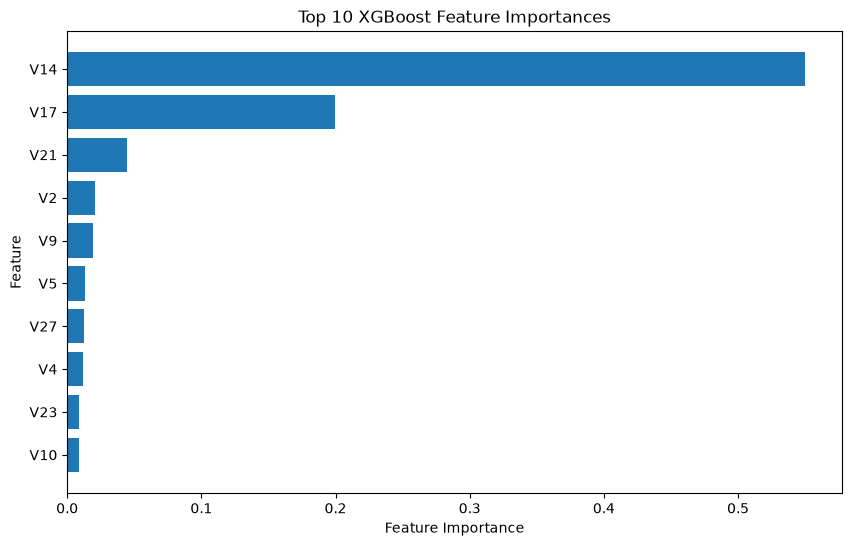

In [134]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 XGBoost Feature Importances")

plt.show()

# final visualization for models

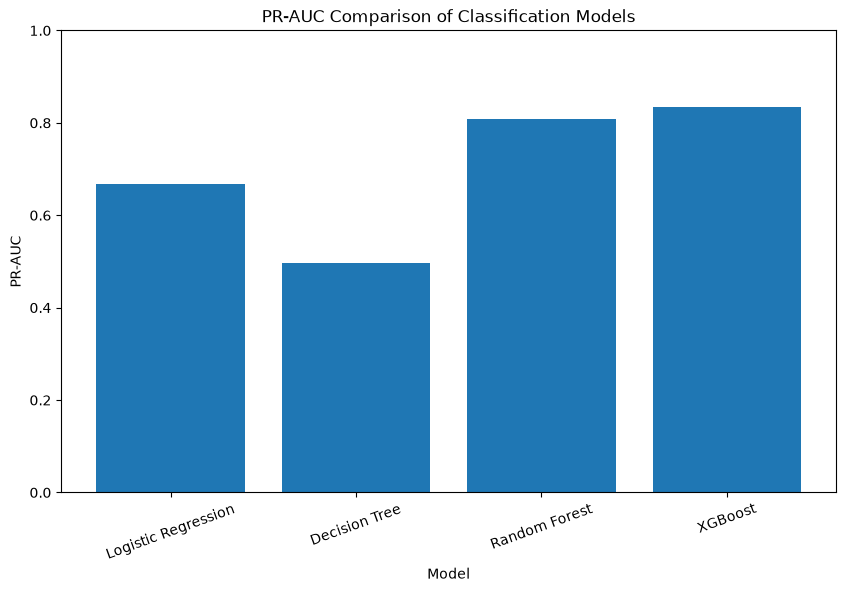

In [142]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    model_comparison["Model"],
    model_comparison["PR-AUC"]
)

plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.title("PR-AUC Comparison of Classification Models")

plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.show()

# visualization for prec rec f1 score

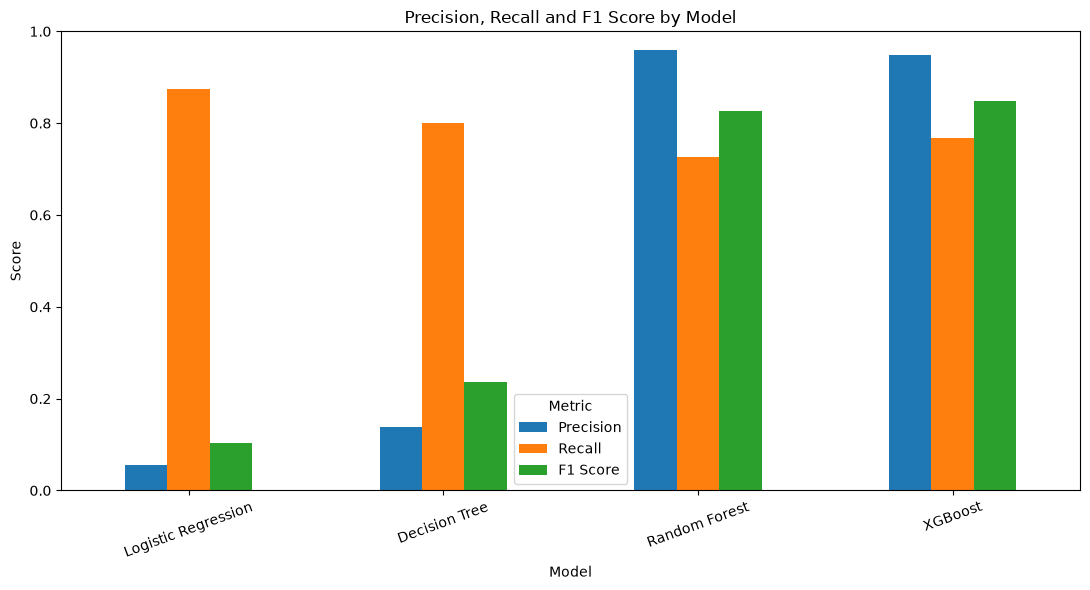

In [144]:
metrics_to_plot = model_comparison.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
]

metrics_to_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Precision, Recall and F1 Score by Model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Metric")
plt.tight_layout()

plt.show()

EDA → preprocessing → train/test/validation split → Logistic Regression → Decision Tree → Random Forest → XGBoost → hyperparameter tuning → threshold selection on validation → final test evaluation → model comparison → feature importance.

# saving the model

In [139]:
import joblib

joblib.dump(
    best_xgb_model,
    "../models/xgboost_fraud_model.pkl"
)

['../models/xgboost_fraud_model.pkl']

# save threshold

In [140]:
model_artifact = {
    "model": best_xgb_model,
    "threshold": best_threshold
}

joblib.dump(
    model_artifact,
    "../models/fraud_detection_model.pkl"
)

['../models/fraud_detection_model.pkl']

# save the table

In [147]:
model_comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

# save feature imp

In [148]:
feature_importance.to_csv(
    "../results/feature_importance.csv",
    index=False
)

# save threshold analysis (val threshold)

In [149]:
threshold_df_val.to_csv(
    "../results/threshold_analysis.csv",
    index=False
)

# testing saved model

In [150]:
import joblib

artifact = joblib.load(
    "../models/fraud_detection_model.pkl"
)

loaded_model = artifact["model"]
loaded_threshold = artifact["threshold"]

print(type(loaded_model))
print("Threshold:", loaded_threshold)

<class 'xgboost.sklearn.XGBClassifier'>
Threshold: 0.30000000000000004


In [151]:
test_probabilities = loaded_model.predict_proba(
    x_test.iloc[:5]
)[:, 1]

test_predictions = (
    test_probabilities >= loaded_threshold
).astype(int)

print("Probabilities:", test_probabilities)
print("Predictions:", test_predictions)
print("Actual:", y_test.iloc[:5].values)

Probabilities: [1.2171589e-06 1.9532085e-06 9.7514021e-06 3.1814500e-07 2.4657818e-06]
Predictions: [0 0 0 0 0]
Actual: [0 0 0 0 0]
